Plot number of patients per center

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import lydata as ly
usz_blue = '#005ea8'
usz_green = '#00afa5'
usz_red = '#ae0060'
usz_orange = '#f17900'
usz_gray = '#c5d5db'

list_centers = pd.read_excel("reduced_list_centers.xlsx")
list_centers.sort_values(by = "Number of patients",inplace = True)

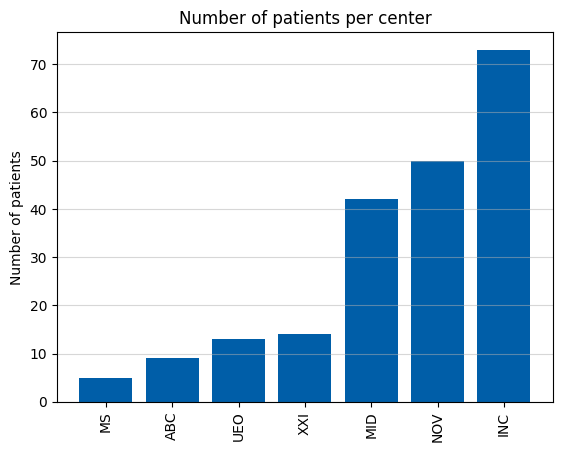

In [30]:
plt.bar(range(len(list_centers)), list_centers["Number of patients"], color = usz_blue)
plt.xticks(range(len(list_centers)), list_centers["Center short"], rotation = 90)
plt.ylabel("Number of patients")
plt.title("Number of patients per center")
plt.grid(axis = "y", alpha = 0.5)
# plt.savefig("number_of_patients_per_center.png", bbox_inches = "tight", dpi = 300)

## Analysis of data

In [31]:
abc = pd.read_excel("updated_datasets/ABC_update.xlsx", header = [0,1,2])
inc = pd.read_excel("updated_datasets/INC_update.xlsx", header = [0,1,2])
mid = pd.read_excel("updated_datasets/MID_update.xlsx", header = [0,1,2])
ms = pd.read_excel("updated_datasets/MS_old.xlsx", header = [0,1,2])
nov = pd.read_excel("updated_datasets/NOV_old.xlsx", header = [0,1,2])
ueo = pd.read_excel("updated_datasets/UEO_update.xlsx", header = [0,1,2])
xxi = pd.read_excel("updated_datasets/XXI_update.xlsx", header = [0,1,2])

In [4]:
datasets = pd.concat([abc, inc, mid, ms, nov, ueo, xxi], ignore_index = True)
# datasets = pd.concat([abc, inc, mid, ueo, xxi], ignore_index = True)

In [5]:
datasets.replace("not recorded", np.nan, inplace = True)
datasets.replace("unknown", np.nan, inplace = True)

C:\Users\yoelh\AppData\Local\Temp\ipykernel_10652\3054759555.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  datasets.replace("unknown", np.nan, inplace = True)


In [6]:
def to_bool(value):
    if isinstance(value, str):
        normalized = value.strip().casefold()
        if normalized == "true":
            return True
        if normalized == "false":
            return False
    return value

datasets = datasets.map(to_bool)

enhanced_datasets = datasets.ly.enhance()

In [7]:
non_empty_rows = enhanced_datasets['max_llh'].notna().any(axis = 1)
dataset_filled = enhanced_datasets[non_empty_rows]
dataset_empty = enhanced_datasets[~non_empty_rows]

three patients with no involvement information

In [8]:
dataset_empty

patient                                                                 \
       core                                                                  
         id age alcohol_abuse        diagnose_date hpv_status  institution   
85    MID-4  34         False  2024-01-19 00:00:00       True  UMAE Merida   
124    MS-1  26         False  2025-05-01 00:00:00        NaN   Medica Sur   
128    MS-5  53         False  2025-10-23 00:00:00       True   Medica Sur   

                                                    ... treated_LNLs        \
                                                    ...         ipsi         
    m_stage n_stage neck_dissection nicotine_abuse  ...          III    IV   
85        0       1           False          False  ...         True  True   
124       0     NaN           False          False  ...         True  True   
128       0       1            True          False  ...         True  True   

                     treatment                                        \
                  chemotherapy                          radiotherapy   
         V    VII      RT_type concomitant neo_adjuvant    number_fx   
85   False  False    IMRT/VMAT        True        False           35   
124  False   True    IMRT/VMAT       False         True           35   
128   True   True    IMRT/VMAT         NaN         True           33   

                                              
                                              
    prescribed_CTVn_dose prescribed_PTV_dose  
85                  50.0               70.00  
124                 54.0               70.00  
128                 52.8               69.96  

[3 rows x 268 columns]

In [9]:
dataset_filled['patient']['core']['institution'].value_counts()

institution
INCAN                                    73
UMAE Merida                              41
CMN20MV                                  28
CMN20GN                                  22
CMN Siglo XXI  Onco                      17
Unidad de Especialidades de Oncología    13
Centro Medico ABC Observatorio            9
Medica Sur                                3
Name: count, dtype: int64

In [10]:
dataset_filled['max_llh']['ipsi'][["I","II","III","IV","V"]].value_counts()

I      II     III    IV     V    
False  False  False  False  False    61
       True   False  False  False    41
              True   False  False    35
       False  True   False  False    11
True   True   True   False  False    10
False  True   True   True   False    10
True   True   True   True   False     8
              False  False  False     8
False  True   True   False  True      5
True   True   True   True   True      4
False  False  True   True   False     3
       True   True   True   True      3
              False  True   False     2
       False  False  False  True      1
       True   False  False  True      1
True   False  False  False  False     1
       True   False  True   False     1
              True   False  True      1
Name: count, dtype: int64

## Big check

In [11]:
dataset_filled['tumor','core','subsite'].value_counts().keys()

Index(['C09', 'C09.0', 'C09.1', 'C01', 'other Oropharynx', 'C05.1', 'C10.8',
       'C09.9', 'C09.8', 'C10', 'C10.2', 'C10.3'],
      dtype='object', name=('tumor', 'core', 'subsite'))

For the 20 Nov 33 patient something went wrong. I will need to build better diagnostic code to explain to me what went wrong.

Things I need:
1. Check where diagnostic consensus contradicts pathology on superlevel!
2. Where superlevel contradicts sublevel in each diagnostic modality
3. make sure that the way I enhance is correct (something seems to be off. But likely due to sens and spec that is assumed for each modality)
4. Later. check what is treated for each patient

In [12]:
import pandas as pd
from IPython.display import display
from lydata.utils import get_default_modalities

from IPython.display import HTML, display

def display_scrollable(df, height=500):
    display(
        HTML(
            f"""
            <div style="max-height:{height}px; overflow:auto;">
                {df.to_html(index=False)}
            </div>
            """
        )
    )

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------

MODALITIES = [
    "CT",
    "FNA",
    "MRI",
    "PET",
    "diagnostic_consensus",
    "pathology",
]

SIDES = ["ipsi", "contra"]

# Main / superlevel representation
MAIN_LEVELS = ["I", "II", "III", "IV", "V", "VII"]

# Only these actually have sublevels in your dataset
SUBDIVISIONS = {
    "I": ["Ia", "Ib"],
    "II": ["IIa", "IIb"],
}

ALL_LEVELS = [
    "I", "Ia", "Ib",
    "II", "IIa", "IIb",
    "III", "IV", "V", "VII",
]

META = {
    "patient_id": ("patient", "core", "id"),
    "institution": ("patient", "core", "institution"),
    "subsite": ("tumor", "core", "subsite"),
}


def _patient_info(df, mask):
    """Small helper to attach useful patient information to every problem."""
    out = pd.DataFrame({"row": df.index[mask]})

    for name, col in META.items():
        if col in df.columns:
            out[name] = df.loc[mask, col].to_numpy()

    return out.reset_index(drop=True)


# ------------------------------------------------------------------
# 1. Compare two modalities at the same LNL
# ------------------------------------------------------------------

def compare_modalities(
    left,
    mod_left,
    mod_right,
    right=None,
    levels=MAIN_LEVELS,
):
    """
    Find cases where two modalities have known but different diagnoses.
    'right' can be another dataframe, e.g. raw pathology vs enhanced max_llh.
    """
    right = left if right is None else right

    if not left.index.equals(right.index):
        raise ValueError("left and right must have the same index.")

    results = []

    for side in SIDES:
        for level in levels:
            col_left = (mod_left, side, level)
            col_right = (mod_right, side, level)

            if col_left not in left.columns or col_right not in right.columns:
                continue

            a = left[col_left]
            b = right[col_right]

            mask = (
                a.notna()
                & b.notna()
                & a.ne(b).fillna(False)
            )

            if mask.any():
                part = _patient_info(left, mask)
                part["side"] = side
                part["level"] = level
                part[mod_left] = a.loc[mask].to_numpy()
                part[mod_right] = b.loc[mask].to_numpy()
                results.append(part)

    return (
        pd.concat(results, ignore_index=True)
        if results else pd.DataFrame()
    )


# ------------------------------------------------------------------
# 2. Check superlevel <-> sublevel consistency
# ------------------------------------------------------------------

def hierarchy_conflicts(df, modalities=MODALITIES):
    """
    Check whether I contradicts Ia/Ib or II contradicts IIa/IIb.
    """
    results = []

    for modality in modalities:
        for side in SIDES:
            for superlevel, children in SUBDIVISIONS.items():

                parent_col = (modality, side, superlevel)
                child_cols = [
                    (modality, side, child)
                    for child in children
                ]

                if (
                    parent_col not in df.columns
                    or not all(col in df.columns for col in child_cols)
                ):
                    continue

                parent = df[parent_col]

                subs = df[child_cols].copy()
                subs.columns = children

                # Infer superlevel only where the sublevels determine it.
                expected = pd.Series(
                    pd.NA,
                    index=df.index,
                    dtype="boolean",
                )

                # Any positive sublevel -> superlevel must be positive
                expected.loc[subs.eq(True).any(axis=1)] = True

                # Both sublevels known and negative -> superlevel must be negative
                expected.loc[
                    subs.notna().all(axis=1)
                    & subs.eq(False).all(axis=1)
                ] = False

                mask = (
                    parent.notna()
                    & expected.notna()
                    & parent.ne(expected).fillna(False)
                )

                if mask.any():
                    part = _patient_info(df, mask)

                    part["modality"] = modality
                    part["side"] = side
                    part["superlevel"] = superlevel
                    part["superlevel_value"] = (
                        parent.loc[mask].to_numpy()
                    )

                    part["sublevels"] = [
                        ", ".join(
                            f"{key}={value}"
                            for key, value in row.items()
                        )
                        for row in subs.loc[mask].to_dict("records")
                    ]

                    part["expected_superlevel"] = (
                        expected.loc[mask].to_numpy()
                    )

                    part["problem"] = [
                        "superlevel=False but a sublevel=True"
                        if value == False
                        else "superlevel=True but all sublevels=False"
                        for value in parent.loc[mask]
                    ]

                    results.append(part)

    return (
        pd.concat(results, ignore_index=True)
        if results else pd.DataFrame()
    )


# ------------------------------------------------------------------
# 3. See exactly what enhance() changed
# ------------------------------------------------------------------

def enhancement_changes(raw, enhanced, modalities=MODALITIES):
    """List every diagnostic value changed by enhance()."""
    results = []

    for modality in modalities:
        for side in SIDES:
            for level in ALL_LEVELS:

                col = (modality, side, level)

                if col not in raw.columns or col not in enhanced.columns:
                    continue

                before = raw[col]
                after = enhanced[col]

                same = (
                    before.eq(after).fillna(False)
                    | (before.isna() & after.isna())
                )

                mask = ~same

                if mask.any():
                    part = _patient_info(raw, mask)

                    part["modality"] = modality
                    part["side"] = side
                    part["level"] = level
                    part["before"] = before.loc[mask].to_numpy()
                    part["after"] = after.loc[mask].to_numpy()

                    results.append(part)

    return (
        pd.concat(results, ignore_index=True)
        if results else pd.DataFrame()
    )

In [13]:
# IMPORTANT: this should be the ORIGINAL, unenhanced dataset
raw = datasets.copy()


# ================================================================
# CHECK 1: diagnostic consensus vs pathology
# ================================================================

consensus_vs_pathology = (
    compare_modalities(
        raw,
        "diagnostic_consensus",
        "pathology",
    )
    .sort_values(
        ["institution", "patient_id", "side", "level"]
    )
    .reset_index(drop=True)
)

print(
    "Diagnostic consensus vs pathology:",
    len(consensus_vs_pathology),
    "conflicts",
)
display_scrollable(consensus_vs_pathology)


# ================================================================
# CHECK 2: superlevel vs sublevel within each modality
# ================================================================

super_sub_conflicts = (
    hierarchy_conflicts(raw)
    .sort_values(
        ["row", "modality", "side", "superlevel"]
    )
    .reset_index(drop=True)
)


print(
    "Superlevel/sublevel conflicts:",
    len(super_sub_conflicts),
)
display_scrollable(super_sub_conflicts)


Diagnostic consensus vs pathology: 150 conflicts


row,patient_id,institution,subsite,side,level,diagnostic_consensus,pathology
131,3,CMN20GN,C09.1,contra,II,True,False
131,3,CMN20GN,C09.1,ipsi,II,True,False
131,3,CMN20GN,C09.1,ipsi,III,True,False
131,3,CMN20GN,C09.1,ipsi,IV,True,False
131,3,CMN20GN,C09.1,ipsi,V,True,False
132,4,CMN20GN,other Oropharynx,ipsi,III,True,False
132,4,CMN20GN,other Oropharynx,ipsi,IV,True,False
135,7,CMN20GN,C10.8,contra,II,True,False
135,7,CMN20GN,C10.8,ipsi,I,True,False
135,7,CMN20GN,C10.8,ipsi,II,True,False


Superlevel/sublevel conflicts: 53


row,patient_id,institution,subsite,modality,side,superlevel,superlevel_value,sublevels,expected_superlevel,problem
98,MID-17,UMAE Merida,C09.0,diagnostic_consensus,ipsi,II,True,"IIa=False, IIb=False",False,superlevel=True but all sublevels=False
127,MS-4,Medica Sur,C05.1,PET,ipsi,II,False,"IIa=True, IIb=False",True,superlevel=False but a sublevel=True
127,MS-4,Medica Sur,C05.1,diagnostic_consensus,ipsi,II,False,"IIa=True, IIb=False",True,superlevel=False but a sublevel=True
127,MS-4,Medica Sur,C05.1,pathology,ipsi,II,False,"IIa=True, IIb=False",True,superlevel=False but a sublevel=True
131,3,CMN20GN,C09.1,CT,contra,II,False,"IIa=True, IIb=True",True,superlevel=False but a sublevel=True
132,4,CMN20GN,other Oropharynx,CT,ipsi,II,False,"IIa=True, IIb=True",True,superlevel=False but a sublevel=True
133,5,CMN20GN,C09.1,CT,ipsi,II,False,"IIa=False, IIb=True",True,superlevel=False but a sublevel=True
135,7,CMN20GN,C10.8,diagnostic_consensus,contra,I,False,"Ia=False, Ib=True",True,superlevel=False but a sublevel=True
136,8,CMN20GN,C09.1,CT,ipsi,II,True,"IIa=False, IIb=False",False,superlevel=True but all sublevels=False
138,10,CMN20GN,C09.1,CT,ipsi,I,False,"Ia=False, Ib=True",True,superlevel=False but a sublevel=True


In [14]:
len(list(consensus_vs_pathology['patient_id'].unique()))

44

In [15]:
consensus_vs_pathology.to_csv("consensus_vs_pathology2.csv", index = False)
super_sub_conflicts.to_csv("super_sub_conflicts2.csv", index = False)

In [16]:
# ================================================================
# CHECK 3: enhance and inspect what it does
# ================================================================

default_configs = get_default_modalities()

configs = {
    modality: default_configs[modality]
    for modality in MODALITIES
}

display_scrollable(pd.DataFrame([
    {
        "modality": name,
        "sensitivity": config.sens,
        "specificity": config.spec,
        "kind": config.kind,
    }
    for name, config in configs.items()
]))


# IMPORTANT: explicitly tell lydata that ONLY I and II are subdivided.
ly_subdivisions = {
    "I": ["a", "b"],
    "II": ["a", "b"],
}

enhanced = raw.ly.enhance(
    modalities=configs,
    method="max_llh",
    subdivisions=ly_subdivisions,
)


# What did enhancement alter in the original modalities?
changes = enhancement_changes(raw, enhanced)

print("Values changed by enhance():", len(changes))
display_scrollable(changes)


# max_llh should not contradict available RAW pathology
maxllh_vs_pathology = compare_modalities(
    enhanced,
    "max_llh",
    "pathology",
    right=raw,
)

print(
    "max_llh vs raw pathology:",
    len(maxllh_vs_pathology),
    "conflicts",
)
display(maxllh_vs_pathology)

modality,sensitivity,specificity,kind
CT,0.81,0.76,clinical
FNA,0.80,0.98,pathological
MRI,0.81,0.63,clinical
PET,0.79,0.86,clinical
diagnostic_consensus,0.81,0.86,clinical
pathology,1.00,1.00,pathological


Values changed by enhance(): 65


row,patient_id,institution,subsite,modality,side,level,before,after
138,10,CMN20GN,C09.1,CT,ipsi,I,False,True
152,24,CMN20MV,other Oropharynx,CT,ipsi,I,False,True
179,UEO-1,Unidad de Especialidades de Oncología,C09.0,CT,ipsi,I,False,True
187,UEO-9,Unidad de Especialidades de Oncología,C09.0,CT,ipsi,I,False,True
132,4,CMN20GN,other Oropharynx,CT,ipsi,II,False,True
133,5,CMN20GN,C09.1,CT,ipsi,II,False,True
178,50,CMN20MV,C09.1,CT,ipsi,II,False,True
180,UEO-2,Unidad de Especialidades de Oncología,C09.0,CT,ipsi,II,False,True
181,UEO-3,Unidad de Especialidades de Oncología,C09.0,CT,ipsi,II,False,True
136,8,CMN20GN,C09.1,CT,ipsi,IIa,False,None


max_llh vs raw pathology: 0 conflicts


""


In [17]:
raw.loc[124]

patient               core   id                                    MS-1
                             institution                     Medica Sur
                             sex                                   male
                             age                                     26
                             diagnose_date          2025-05-01 00:00:00
                                                           ...         
outcome               core   date_last_follow_up             22/05/2026
                             survival_status           ALIVE WO/DISEASE
patient               core   comments                               NaN
                      EXPED  Unnamed: 1_level_2                     NaN
diagnostic_consensus  core   exped                                  NaN
Name: 124, Length: 220, dtype: object

In [ ]:
from pathlib import Path
from datetime import datetime
import re
import math

import pandas as pd
from openpyxl.styles import Alignment, Font, PatternFill


SIDE_ES = {
    "ipsi": "ipsilateral",
    "contra": "contralateral",
}

MODALITY_ES = {
    "CT": "CT",
    "FNA": "FNA",
    "MRI": "MRI",
    "PET": "PET",
    "diagnostic_consensus": "consenso diagnóstico",
    "pathology": "patología",
}


def value_es(value):
    """Translate involvement values while preserving missing information."""
    if pd.isna(value):
        return "no registrado"

    text = str(value).strip().lower()
    return {
        "true": "positivo",
        "1": "positivo",
        "1.0": "positivo",
        "false": "negativo",
        "0": "negativo",
        "0.0": "negativo",
        "nan": "no registrado",
        "none": "no registrado",
        "<na>": "no registrado",
    }.get(text, str(value))


# Collect all observations in one common format.
observations = []


def add_observation(row, text):
    if pd.isna(row["institution"]) or pd.isna(row["patient_id"]):
        raise ValueError(
            "An issue has a missing institution or patient ID. "
            "Resolve this before generating centre feedback."
        )

    observations.append({
        "Centro": str(row["institution"]).strip(),
        "ID del paciente": str(row["patient_id"]).strip(),
        "Subsitio": (
            str(row["subsite"]) if pd.notna(row["subsite"]) else ""
        ),
        "Observación": text,
    })


# 1. Diagnostic consensus versus pathology.
for _, row in consensus_vs_pathology.iterrows():
    side = SIDE_ES[row["side"]]

    text = (
        f"Consenso diagnóstico vs. patología — lado {side}, "
        f"nivel {row['level']}: "
        f"consenso diagnóstico = {value_es(row['diagnostic_consensus'])}; "
        f"patología = {value_es(row['pathology'])}. "
        "Confirmar ambos valores o indicar la corrección."
    )
    add_observation(row, text)


# 2. Main-level versus sublevel inconsistencies.
for _, row in super_sub_conflicts.iterrows():
    side = SIDE_ES[row["side"]]
    modality = MODALITY_ES.get(row["modality"], row["modality"])

    translated_sublevels = []
    for item in row["sublevels"].split(","):
        level, value = item.strip().split("=", 1)
        translated_sublevels.append(f"{level} = {value_es(value)}")

    if value_es(row["superlevel_value"]) == "negativo":
        explanation = (
            "El nivel principal figura como negativo, "
            "pero al menos un subnivel es positivo."
        )
    else:
        explanation = (
            "El nivel principal figura como positivo, "
            "pero ambos subniveles son negativos."
        )

    text = (
        f"Nivel principal vs. subniveles — {modality}, lado {side}: "
        f"{row['superlevel']} = {value_es(row['superlevel_value'])}; "
        f"{'; '.join(translated_sublevels)}. "
        f"{explanation} Verificar los valores registrados."
    )
    add_observation(row, text)


# 3. Additional sanity checks on the full, unenhanced cohort.
# Reload so notebook reruns use the current checking rules.
import importlib
from scripts import sanity_checks
importlib.reload(sanity_checks)
# Choose mode="full" to include all historical checks.
sanity_issues = sanity_checks.run_sanity_checks(raw, mode="reduced", stage_basis=None)

for _, row in sanity_issues.iterrows():
    add_observation(row, f"{row['category']}: {row['details']}")


# Combine all observations for each patient within each centre.
patient_rows = []

if observations:
    detail = pd.DataFrame(observations)

    for (centre, patient_id), group in detail.groupby(
        ["Centro", "ID del paciente"], sort=True
    ):
        patient_rows.append({
            "Centro": centre,
            "ID del paciente": patient_id,
            "Subsitio": ", ".join(
                dict.fromkeys(s for s in group["Subsitio"] if s)
            ),
            "N.º de observaciones": len(group),
            "Observaciones para revisar": "\n\n".join(
                f"{i}. {text}"
                for i, text in enumerate(group["Observación"], start=1)
            ),
            "Respuesta / correcciones del centro": "",
        })

feedback_por_paciente = pd.DataFrame(patient_rows)


# Export one workbook per centre into a new folder on each run.
if feedback_por_paciente.empty:
    print("No se encontraron observaciones en las comprobaciones.")
else:
    output_dir = (
        Path("Feedback_tabels")
        / f"por_paciente_{datetime.now():%Y%m%d_%H%M%S_%f}"
    )
    output_dir.mkdir(parents=True, exist_ok=False)

    instructions = pd.DataFrame({
        "Indicaciones": [
            "Cada fila corresponde a un paciente y reúne todas las "
            "observaciones detectadas en las comprobaciones de discrepancias y los controles adicionales de calidad.",

            "Positivo = afectación registrada; negativo = ausencia de "
            "afectación registrada; no registrado = información desconocida.",

            "Revisar cada observación con los registros originales. "
            "Indicar las correcciones o confirmar los valores en la "
            "columna de respuesta, citando el número de observación.",

            "Una discrepancia entre consenso diagnóstico y patología "
            "no implica necesariamente un error. Si ambos valores son "
            "correctos, confirmarlos y añadir una explicación.",

            "Estas tablas incluyen discrepancias entre consenso y patología "
            "en los niveles I, II, III, IV, V y VII, e inconsistencias entre "
            "I y Ia/Ib o entre II y IIa/IIb, en ambos lados.",
        ]
    })
    instructions.loc[len(instructions)] = [
        f"Modo de controles adicionales: {sanity_issues.attrs['mode']}. "
        "Los controles adicionales incluyen identificación, valores no válidos, "
        "concordancia del estadio N, contradicciones en recuentos y resultados de disección cervical. "
        "El modo completo añade controles de fechas, datos faltantes y recuentos. "
        "Los hallazgos del estadio N requieren contexto clínico."
    ]

    for number, (centre, table) in enumerate(
        feedback_por_paciente.groupby("Centro", sort=True), start=1
    ):
        safe_name = re.sub(r"[^\w-]+", "_", centre).strip("_")[:90]
        output_file = output_dir / f"{number:02d}_{safe_name}.xlsx"

        with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
            table.to_excel(writer, sheet_name="Pacientes", index=False)
            instructions.to_excel(
                writer, sheet_name="Indicaciones", index=False
            )

            ws = writer.sheets["Pacientes"]
            ws.freeze_panes = "C2"
            ws.auto_filter.ref = ws.dimensions

            widths = {
                "A": 40, "B": 20, "C": 22,
                "D": 18, "E": 100, "F": 60,
            }
            for column, width in widths.items():
                ws.column_dimensions[column].width = width

            for row in ws.iter_rows(min_row=2):
                for cell in row:
                    cell.alignment = Alignment(
                        vertical="top", wrap_text=True
                    )

                # Keep patient IDs as text and make long observations readable.
                row[1].number_format = "@"
                text = str(row[4].value or "")
                estimated_lines = sum(
                    max(1, math.ceil(len(line) / 85))
                    for line in text.split("\n")
                )
                ws.row_dimensions[row[0].row].height = min(
                    409, max(60, 16 * (estimated_lines + 1))
                )

            notes = writer.sheets["Indicaciones"]
            notes.column_dimensions["A"].width = 110
            for row in notes.iter_rows(min_row=2):
                row[0].alignment = Alignment(
                    vertical="top", wrap_text=True
                )
                notes.row_dimensions[row[0].row].height = 60

            for sheet in (ws, notes):
                sheet.row_dimensions[1].height = 32
                for cell in sheet[1]:
                    cell.fill = PatternFill(
                        "solid", fgColor="005EA8"
                    )
                    cell.font = Font(color="FFFFFF", bold=True)
                    cell.alignment = Alignment(
                        vertical="center", wrap_text=True
                    )

        print(f"{centre}: {len(table)} pacientes → {output_file.name}")

    print(f"\nArchivos guardados en: {output_dir.resolve()}")
    display(feedback_por_paciente)

## Do more sanity checks

In [ ]:
import importlib
from scripts import sanity_checks
importlib.reload(sanity_checks)

# Use the full, unenhanced dataset.
# Leave stage_basis=None until clinical/pathological staging is confirmed.
# Choose mode="full" to include all historical checks.
sanity_issues = sanity_checks.run_sanity_checks(raw, mode="reduced", stage_basis=None)

display(sanity_issues)

display(
    sanity_issues.groupby(["check", "category"])
    .size()
    .rename("Number of observations")
    .reset_index()
)